# **<span style="color: #0000ff;"> S4.1 Satisfaction Rate and Corresponding Wilson Confidence Interval </span>**

**Given:**

$n$ is the number of participants<br>
$k$ is the number of participants with SAT >= 4 <br>
$\hat p = k/n$ is the observed satisfaction rate

$n=510$,<br>
$k=360$,<br> 
$\hat p\approx 70.6\%$

The formula for the 95% Wilson confidence interval is:
$$
\left[
\frac{\hat p+\frac{z^2}{2n}
-z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}
{1+\frac{z^2}{n}},
\quad
\frac{\hat p+\frac{z^2}{2n}
+z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}
{1+\frac{z^2}{n}}
\right]
$$

For a two-sided 95% confidence level, $z=\Phi^{-1}(0.975)\approx 1.96$.
The 95% Wilson interval is **66.5%-74.4%**.

In [2]:
import math
from pathlib import Path
import pandas as pd

csv_path = Path("Satisfaction/gacha_clean.csv")
if not csv_path.exists():
    csv_path = Path("gacha_clean.csv")
df = pd.read_csv(csv_path, encoding="utf-8-sig")

# Validate the data.
assert df["SAT"].notna().all(), "Check whether SAT contains missing values"
assert df["SAT"].between(1, 5).all(), "Check whether SAT contains values outside the 1–5 scale (invalid data)"

n = len(df)  # Number of respondents.
k = int((df["SAT"] >= 4).sum())  # Number of satisfied respondents.
p = k / n  # Satisfaction rate.

# Calculate the 95% Wilson confidence interval.
z = 1.95996398454
denominator = 1 + z**2 / n # Calculate the denominator in the Wilson formula
centre = (p + z**2 / (2 * n)) / denominator # Calculate the center of the Wilson interval
margin = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator # Calculate the margin of the Wilson interval
lower = centre - margin # Lower bound
upper = centre + margin # Upper bound

print(f"Respondents: {n}")
print(f"Satisfied (SAT >= 4): {k}")
print(f"Satisfaction rate: {p:.1%}")
print(f"Wilson 95% CI: {lower:.1%} - {upper:.1%}")


Respondents: 510
Satisfied (SAT >= 4): 360
Satisfaction rate: 70.6%
Wilson 95% CI: 66.5% - 74.4%


### **S4.2.1 Satisfaction Rate by Monthly Spending Group**

Define a function to calculate the Wilson confidence interval for each group, using the same formula as in Step 4.1.

**Function name: <span style="color: #00ffff;"> wilson_ci </span>**

Loop through each group and create a table for easier inspection.

**The table contains:**
- Spending group
- Total number of respondents in the group
- Number of satisfied respondents in the group
- Satisfaction rate
- Lower confidence bound
- Upper confidence bound

In [3]:
# Define a function to calculate the Wilson confidence interval
def wilson_ci(k, n, z=1.95996398454):
    p = k / n
    denominator = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denominator
    margin = (
        z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
        / denominator
    )
    return centre - margin, centre + margin


rows = []
# Calculate results for each spending group
for group, data in df.groupby("SPEND_MONTH4", sort=True):
    n_group = len(data)
    k_group = int((data["SAT"] >= 4).sum())
    lower_group, upper_group = wilson_ci(k_group, n_group)

    rows.append({
        "Spending group": int(group),
        "Respondents": n_group,
        "Satisfied respondents": k_group,
        "Rate (%)": 100 * k_group / n_group,
        "CI lower (%)": 100 * lower_group,
        "CI upper (%)": 100 * upper_group,
    })

s4_2 = pd.DataFrame(rows)
display(s4_2.round(1))

,Spending group,Respondents,Satisfied respondents,Rate (%),CI lower (%),CI upper (%)
0,0,218,154,70.6,64.3,76.3
1,1,110,78,70.9,61.8,78.6
2,2,131,91,69.5,61.1,76.7
3,3,51,37,72.5,59.1,82.9


## **S4.2.2 Combined Bar and Line Chart**

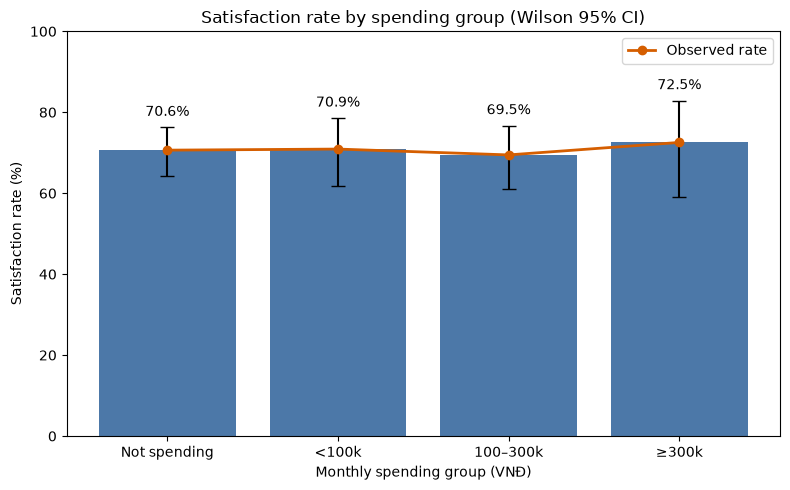

In [4]:
import matplotlib.pyplot as plt

labels = ["Not spending", "<100k", "100–300k", "≥300k"]
rates = s4_2["Rate (%)"].to_numpy()
lower_errors = rates - s4_2["CI lower (%)"].to_numpy()
upper_errors = s4_2["CI upper (%)"].to_numpy() - rates

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    labels,
    rates,
    yerr=[lower_errors, upper_errors],
    capsize=5,
    color="#4C78A8",
    ecolor="black",
)
ax.plot(
    range(len(rates)),
    rates,
    marker="o",
    color="#D55E00",
    linewidth=2,
    label="Observed rate",
)
ax.legend()
ax.set_ylim(0, 100)
ax.set_ylabel("Satisfaction rate (%)")
ax.set_xlabel("Monthly spending group (VND)")
ax.set_title("Satisfaction rate by spending group (Wilson 95% CI)")

for i, rate in enumerate(rates):
    ax.text(i, rate + upper_errors[i] + 2, f"{rate:.1f}%",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()

### **Commentary:**
Satisfaction rates across the four spending groups range from 69.5% to 72.5%. The descriptive statistics show no clear upward or downward trend by spending level. The group spending at least 300,000 VND per month has 51 respondents, so its confidence interval is wider than those of the other groups. These results describe an association in the survey sample; they do not show that spending affects satisfaction.

## **S4.3 Satisfaction Rates by Group**
**This section contains four tables:**
- Satisfaction rate by game-playing tenure
- Satisfaction rate by game title
- Satisfaction rate by in-game reward outcome (WON_FEATURED)
- Satisfaction rate by the respondent's current status (STATUS)

In [5]:
def satisfaction_by_group(df, column):
    rows = []

    for group, data in df.groupby(column):
        n_group = len(data)
        k_group = int((data["SAT"] >= 4).sum())
        p_group = k_group / n_group

        # Wilson 95% CI
        z = 1.95996398454
        den = 1 + z**2 / n_group
        centre = (p_group + z**2 / (2 * n_group)) / den
        margin = (
            z * math.sqrt(
                p_group * (1 - p_group) / n_group
                + z**2 / (4 * n_group**2)
            ) / den
        )

        rows.append({
            "Group": group,
            "n": n_group,
            "Satisfied": k_group,
            "Rate (%)": 100 * p_group,
            "CI lower (%)": 100 * (centre - margin),
            "CI upper (%)": 100 * (centre + margin),
            "Mean SAT": data["SAT"].mean(),
        })

    return pd.DataFrame(rows)

for column in ["TENURE", "GAME", "WON_FEATURED", "STATUS"]:
    print(f"\nSatisfaction by {column}")
    display(satisfaction_by_group(df, column).round(1))


Satisfaction by TENURE


,Group,n,Satisfied,Rate (%),CI lower (%),CI upper (%),Mean SAT
0,1-2 years,137,108,78.8,71.3,84.8,4.3
1,6-12 months,35,24,68.6,52.0,81.4,4.1
2,Less than 6 months,35,21,60.0,43.6,74.4,4.1
3,More than 2 years,303,207,68.3,62.9,73.3,4.0



Satisfaction by GAME


,Group,n,Satisfied,Rate (%),CI lower (%),CI upper (%),Mean SAT
0,Genshin,151,101,66.9,59.0,73.9,4.0
1,HSR,81,49,60.5,49.6,70.4,3.8
2,Other,33,19,57.6,40.8,72.8,4.0
3,WuWa,26,18,69.2,50.0,83.5,4.0
4,ZZZ,219,173,79.0,73.1,83.9,4.3



Satisfaction by WON_FEATURED


,Group,n,Satisfied,Rate (%),CI lower (%),CI upper (%),Mean SAT
0,Guarantee,128,79,61.7,53.1,69.7,3.9
1,No,38,21,55.3,39.7,69.9,3.7
2,Won 50/50,344,260,75.6,70.8,79.8,4.2



Satisfaction by STATUS


,Group,n,Satisfied,Rate (%),CI lower (%),CI upper (%),Mean SAT
0,"Active, playing as usual",382,295,77.2,72.8,81.1,4.2
1,Playing much less than before,111,60,54.1,44.8,63.0,3.7
2,Quit in the last 6 months,17,5,29.4,13.3,53.1,3.3


### **Comments on the Tables**
- By playing tenure (TENURE): the 1-2 year group has the highest satisfaction rate at 78.8% (108/137). The under-6-month group is at 60.0% (21/35), while the over-2-year group is at 68.3% (207/303). The rate does not increase steadily with tenure; the two groups with 35 respondents have fairly wide confidence intervals.

- By game (GAME): ZZZ is highest at 79.0% (173/219), while HSR is at 60.5% (49/81). The Other group (33 respondents) and WuWa group (26 respondents) are small, so their rates should be compared cautiously with those for larger groups. Other also combines several different games.

- By banner outcome (WON_FEATURED): the group that won the 50/50 has a satisfaction rate of 75.6% (260/344), compared with 61.7% (79/128) for those who obtained the featured character through the guarantee and 55.3% (21/38) for those who did not obtain the character. This is an association in the survey; it does not establish that banner outcomes cause differences in satisfaction.

- By status (STATUS): respondents who are still playing as usual have a satisfaction rate of 77.2% (295/382), compared with 54.1% (60/111) for those playing less and 29.4% (5/17) for those who have quit. This is the clearest descriptive difference among the four tables, but the quit group has only 17 respondents; its 95% Wilson CI is wide, from 13.3% to 53.1%.

# **S4.4 Sensitivity Analysis**

Compare three definitions of satisfaction: `SAT >= 4` (the primary analysis),
`SAT >= 3.5`, and `SAT2 >= 4`. `SAT2` is the average of Q22-Q23.
The aim is to check whether the rates and conclusions by spending group change
when the threshold or scoring method changes.

In [6]:
scenarios = [
    ("SAT >= 4 (primary)", "SAT", 4),
    ("SAT >= 3.5", "SAT", 3.5),
    ("SAT2 >= 4", "SAT2", 4),
]

rows = []

for name, score_column, cutoff in scenarios:
    # Overall sample results
    n_all = len(df)
    k_all = int((df[score_column] >= cutoff).sum())

    rows.append({
        "Definition": name,
        "Spending group": "Overall sample",
        "n": n_all,
        "Satisfied": k_all,
        "Rate (%)": 100 * k_all / n_all,
    })

    # Results by spending group
    for group, data in df.groupby("SPEND_MONTH4", sort=True):
        n_group = len(data)
        k_group = int((data[score_column] >= cutoff).sum())

        rows.append({
            "Definition": name,
            "Spending group": int(group),
            "n": n_group,
            "Satisfied": k_group,
            "Rate (%)": 100 * k_group / n_group,
        })

s4_4 = pd.DataFrame(rows)
display(s4_4.round(1))

,Definition,Spending group,n,Satisfied,Rate (%)
0,SAT ≥ 4 (primary),Overall sample,510,360,70.6
1,SAT ≥ 4 (primary),0,218,154,70.6
2,SAT ≥ 4 (primary),1,110,78,70.9
3,SAT ≥ 4 (primary),2,131,91,69.5
4,SAT ≥ 4 (primary),3,51,37,72.5
5,SAT >= 3.5,Overall sample,510,413,81.0
6,SAT >= 3.5,0,218,173,79.4
7,SAT >= 3.5,1,110,87,79.1
8,SAT >= 3.5,2,131,109,83.2
9,SAT >= 3.5,3,51,44,86.3


In [7]:
group_order = ["Overall sample", 0, 1, 2, 3]
scenario_order = ["SAT >= 4 (primary)", "SAT >= 3.5", "SAT2 >= 4"]

comparison = s4_4.pivot(
    index="Spending group",
    columns="Definition",
    values="Rate (%)",
).loc[group_order, scenario_order]

# Get each row sample size from the primary analysis results.
group_sizes = (
    s4_4[s4_4["Definition"] == "SAT >= 4 (primary)"]
    .set_index("Spending group")["n"]
    .loc[group_order]
)
comparison.insert(0, "n", group_sizes)

comparison.index = [
    "Overall sample",
    "0 — No spending",
    "1 — Under 100k",
    "2 — 100–300k",
    "3 — 300k or more",
]
comparison.index.name = "Monthly spending group"
comparison.columns.name = None

display(comparison.round(1))

,n,SAT ≥ 4 (primary),SAT >= 3.5,SAT2 >= 4
Monthly spending group,,,,
Overall sample,510,70.6,81.0,77.6
0 — No spending,218,70.6,79.4,77.5
1 — Under 100k,110,70.9,79.1,76.4
2 — 100–300k,131,69.5,83.2,77.1
3 — 300k or more,51,72.5,86.3,82.4


### **Comments on the Table**

Lowering the satisfaction threshold to 3.5 or using only Q22-Q23 increases the overall satisfaction rate from 70.6% to 81.0% and 77.6%, respectively. The specific rate is therefore sensitive to how satisfaction is defined. However, none of the three definitions shows a steady increase across the four spending groups. The group spending at least 300,000 VND per month has the highest rate under all three definitions, but it has only 51 respondents, so the difference should be interpreted cautiously.

In [8]:
import math
import pandas as pd
from IPython.display import display

def wilson_ci(k, n, z=1.95996398454):
    """Return the lower and upper bounds of the 95% Wilson interval."""
    if n == 0:
        return float("nan"), float("nan")

    p = k / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    margin = z * math.sqrt(
        p * (1 - p) / n + z**2 / (4 * n**2)
    ) / denominator
    return center - margin, center + margin

group_names = {
    0: "0 — No spending",
    1: "1 — Under 100k",
    2: "2 — 100–300k",
    3: "3 — 300k or more",
}

scenarios = {
    "SAT >= 4 (primary)": ("SAT", 4),
    "SAT >= 3.5": ("SAT", 3.5),
    "SAT2 >= 4": ("SAT2", 4),
}

rows = []

for group_name, data in [
    ("Overall sample", df),
    *[
        (group_names[g], df[df["SPEND_MONTH4"] == g])
        for g in group_names
    ],
]:
    row = {"Monthly spending group": group_name, "n": len(data)}

    for label, (column, threshold) in scenarios.items():
        k = int((data[column] >= threshold).sum())
        lower, upper = wilson_ci(k, len(data))

        row[label] = f"{k / len(data):.1%}"
        row[f"Wilson 95% — {label}"] = f"{lower:.1%}–{upper:.1%}"

    rows.append(row)

wilson_comparison = pd.DataFrame(rows).set_index("Monthly spending group")
display(wilson_comparison)

,n,SAT ≥ 4 (primary),Wilson 95% — SAT ≥ 4 (primary),SAT >= 3.5,Wilson 95% — SAT >= 3.5,SAT2 >= 4,Wilson 95% — SAT2 >= 4
Monthly spending group,,,,,,,
Overall sample,510,70.6%,66.5%–74.4%,81.0%,77.3%–84.1%,77.6%,73.8%–81.0%
0 — No spending,218,70.6%,64.3%–76.3%,79.4%,73.5%–84.2%,77.5%,71.5%–82.6%
1 — Under 100k,110,70.9%,61.8%–78.6%,79.1%,70.6%–85.6%,76.4%,67.6%–83.3%
2 — 100–300k,131,69.5%,61.1%–76.7%,83.2%,75.9%–88.6%,77.1%,69.2%–83.5%
3 — 300k or more,51,72.5%,59.1%–82.9%,86.3%,74.3%–93.2%,82.4%,69.7%–90.4%


In [10]:
word_table = pd.DataFrame(index=wilson_comparison.index)
word_table["n"] = wilson_comparison["n"]

for label in scenarios:
    word_table[label] = (
        wilson_comparison[label]
        + " ("
        + wilson_comparison[f"Wilson 95% — {label}"]
        + ")"
    )

display(word_table)
word_table.to_clipboard(excel=True)

,n,SAT ≥ 4 (primary),SAT >= 3.5,SAT2 >= 4
Monthly spending group,,,,
Overall sample,510,70.6% (66.5%–74.4%),81.0% (77.3%–84.1%),77.6% (73.8%–81.0%)
0 — No spending,218,70.6% (64.3%–76.3%),79.4% (73.5%–84.2%),77.5% (71.5%–82.6%)
1 — Under 100k,110,70.9% (61.8%–78.6%),79.1% (70.6%–85.6%),76.4% (67.6%–83.3%)
2 — 100–300k,131,69.5% (61.1%–76.7%),83.2% (75.9%–88.6%),77.1% (69.2%–83.5%)
3 — 300k or more,51,72.5% (59.1%–82.9%),86.3% (74.3%–93.2%),82.4% (69.7%–90.4%)
